# Лабораторна робота №6
## Тема: Нейронна регресія для табличних даних у TensorFlow
* **Мета:** Навчитися готувати реальні табличні дані без витоку інформації, порівнювати нейромережу з класичними моделями, контролювати навчання за `validation`, аналізувати помилки та зберігати весь процес прогнозування.
* **Студент:** Заболотний Назар
* **Група:** МІТ-31
* **Варіант:** №8 (зміна `batch_size = 16` відносно базової мережі з `batch_size = 32`)

### Паспорт даних та препроцесора
* **Джерело:** UCI Machine Learning Repository — Auto MPG (`DOI: 10.24432/C5859H`), ліцензія CC BY 4.0.
* **Цільова змінна (`mpg`):** витрата пального в милях на галон (числова величина, більше значення відповідає вищій паливній ефективності).
* **Ознаки (`X`):** 6 числових (`cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, `model_year`) та 1 категоріальна (`origin` — регіон походження авто: 1, 2, 3). Поле `car_name` виключено як текстовий ідентифікатор.

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
keras.utils.set_random_seed(SEED)

print("Версії бібліотек:")
print(f"Python/NumPy: {np.__version__} | Pandas: {pd.__version__} | Scikit-learn: {sklearn.__version__} | TensorFlow: {tf.__version__}")

columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin", "car_name"
]
df = pd.read_csv("auto-mpg.data", sep=r"\s+", names=columns, na_values="?")

print("\nФорма таблиці:", df.shape)
display(df.head())
print("\nТипи даних (dtypes):\n", df.dtypes)
print("\nКількість пропусків по стовпцях:\n", df.isna().sum())
print("\nКількість дублікатів:", df.duplicated().sum())

X = df.drop(columns=["mpg", "car_name"])
y = df["mpg"].astype(np.float32)

/Users/nazarzabolotniy/Desktop/Data_Science_Labs/.venv_tf/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Версії бібліотек:
Python/NumPy: 2.0.2 | Pandas: 2.3.3 | Scikit-learn: 1.6.1 | TensorFlow: 2.20.0

Форма таблиці: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino



Типи даних (dtypes):
 mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name         object
dtype: object

Кількість пропусків по стовпцях:
 mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Кількість дублікатів: 0


In [2]:
# Поділ ~70/15/15 без заповнення пропусків до поділу
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.15 / 0.85, random_state=SEED
)

print(f"Розміри вибірок -> train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}")
# Перевірка відсутності спільних індексів
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

numeric_features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
categorical_features = ["origin"]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), categorical_features)
])

X_train_ready = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocessor.transform(X_val).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)

feature_names = preprocessor.get_feature_names_out().tolist()
print("Ознаки після препроцесингу:", feature_names)
assert np.isfinite(X_train_ready).all() and np.isfinite(X_val_ready).all() and np.isfinite(X_test_ready).all()

Розміри вибірок -> train: (278, 7), val: (60, 7), test: (60, 7)
Ознаки після препроцесингу: ['num__cylinders', 'num__displacement', 'num__horsepower', 'num__weight', 'num__acceleration', 'num__model_year', 'cat__origin_1', 'cat__origin_2', 'cat__origin_3']


In [3]:
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2 = r2_score(y_true, y_pred)
    return {"MAE": float(mae), "RMSE": float(rmse), "R2": float(r2)}

# 1. DummyRegressor
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train_ready, y_train)
val_pred_dummy = dummy_model.predict(X_val_ready)

# 2. LinearRegression (зі StandardScaler)
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])
lr_model.fit(X_train_ready, y_train)
val_pred_lr = lr_model.predict(X_val_ready)

print("Validation Dummy:", regression_metrics(y_val, val_pred_dummy))
print("Validation LinearRegression:", regression_metrics(y_val, val_pred_lr))

Validation Dummy: {'MAE': 7.354940414428711, 'RMSE': 8.611852825857992, 'R2': -3.6835670471191406e-05}
Validation LinearRegression: {'MAE': 2.9013044834136963, 'RMSE': 3.6102498633228364, 'R2': 0.8242491483688354}


--- Summary базової мережі ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428 (5.58 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428 (5.58 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

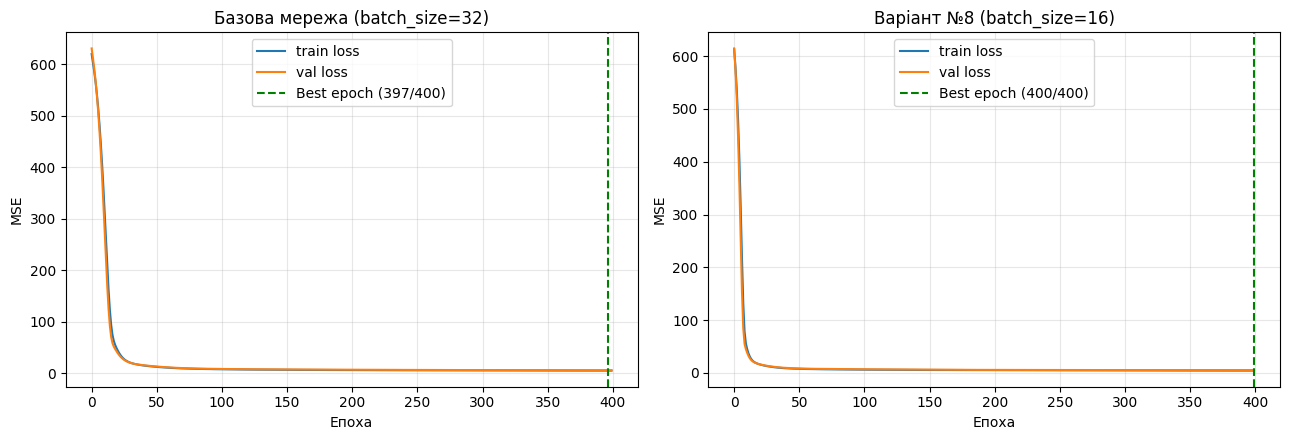

In [4]:
def create_nn(X_train_arr):
    normalizer = layers.Normalization(axis=-1)
    normalizer.adapt(X_train_arr)
    m = keras.Sequential([
        layers.Input(shape=(X_train_arr.shape[1],)),
        normalizer,
        layers.Dense(32, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1),
    ])
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )
    return m

y_train_nn = y_train.to_numpy().reshape(-1, 1)
y_val_nn = y_val.to_numpy().reshape(-1, 1)

# --- 1. Базова нейромережа (batch_size = 32) ---
keras.utils.set_random_seed(SEED)
nn_base = create_nn(X_train_ready)
print("--- Summary базової мережі ---")
nn_base.summary()

base_ckpt = "artifacts/baseline_best.keras"
hist_base = nn_base.fit(
    X_train_ready, y_train_nn,
    validation_data=(X_val_ready, y_val_nn),
    epochs=400,
    batch_size=32,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=20, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(base_ckpt, monitor="val_loss", mode="min", save_best_only=True)
    ],
    verbose=0
)
best_nn_base = keras.models.load_model(base_ckpt)

# --- 2. Варіант №8 (batch_size = 16) ---
keras.utils.set_random_seed(SEED)
nn_var8 = create_nn(X_train_ready)
print("\n--- Summary мережі Варіанта №8 ---")
nn_var8.summary()

var8_ckpt = "artifacts/var8_best.keras"
hist_var8 = nn_var8.fit(
    X_train_ready, y_train_nn,
    validation_data=(X_val_ready, y_val_nn),
    epochs=400,
    batch_size=16,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=20, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(var8_ckpt, monitor="val_loss", mode="min", save_best_only=True)
    ],
    verbose=0
)
best_nn_var8 = keras.models.load_model(var8_ckpt)

# Графіки навчання
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, hist, title in zip(
    axes,
    [hist_base, hist_var8],
    ["Базова мережа (batch_size=32)", "Варіант №8 (batch_size=16)"]
):
    best_ep = int(np.argmin(hist.history["val_loss"])) + 1
    total_ep = len(hist.history["val_loss"])
    ax.plot(hist.history["loss"], label="train loss")
    ax.plot(hist.history["val_loss"], label="val loss")
    ax.axvline(best_ep - 1, color="green", linestyle="--", label=f"Best epoch ({best_ep}/{total_ep})")
    ax.set_title(title)
    ax.set_xlabel("Епоха")
    ax.set_ylabel("MSE")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("lab6_learning_curves.png", dpi=300)
plt.show()

In [5]:
val_pred_base = best_nn_base.predict(X_val_ready, verbose=0).flatten()
val_pred_var8 = best_nn_var8.predict(X_val_ready, verbose=0).flatten()

val_metrics = {
    "DummyRegressor": regression_metrics(y_val, val_pred_dummy),
    "LinearRegression": regression_metrics(y_val, val_pred_lr),
    "NN_Base (batch=32)": regression_metrics(y_val, val_pred_base),
    "NN_Var8 (batch=16)": regression_metrics(y_val, val_pred_var8),
}

# Вибір найкращої нейромережі та найкращого алгоритму за validation RMSE
best_nn_name = "NN_Var8 (batch=16)" if val_metrics["NN_Var8 (batch=16)"]["RMSE"] < val_metrics["NN_Base (batch=32)"]["RMSE"] else "NN_Base (batch=32)"
best_nn_model = best_nn_var8 if best_nn_name == "NN_Var8 (batch=16)" else best_nn_base
best_overall_name = min(val_metrics, key=lambda k: val_metrics[k]["RMSE"])

print(f"Рішення за Validation -> Краща нейромережа: {best_nn_name} | Кращий алгоритм загалом: {best_overall_name}")

# Один раз оцінюємо фінальні моделі на test
test_preds = {
    "DummyRegressor": dummy_model.predict(X_test_ready),
    "LinearRegression": lr_model.predict(X_test_ready),
    "NN_Base (batch=32)": best_nn_base.predict(X_test_ready, verbose=0).flatten(),
    "NN_Var8 (batch=16)": best_nn_var8.predict(X_test_ready, verbose=0).flatten(),
}

epochs_info = {
    "DummyRegressor": ("-", "-"),
    "LinearRegression": ("-", "-"),
    "NN_Base (batch=32)": (len(hist_base.history["val_loss"]), int(np.argmin(hist_base.history["val_loss"])) + 1),
    "NN_Var8 (batch=16)": (len(hist_var8.history["val_loss"]), int(np.argmin(hist_var8.history["val_loss"])) + 1),
}

summary_rows = []
for name in val_metrics:
    tm = regression_metrics(y_test, test_preds[name])
    summary_rows.append({
        "Модель": name,
        "Val RMSE": val_metrics[name]["RMSE"],
        "Test MAE": tm["MAE"],
        "Test RMSE": tm["RMSE"],
        "Test R2": tm["R2"],
        "Факт. епох": epochs_info[name][0],
        "Найкраща епоха": epochs_info[name][1],
    })

comparison_table = pd.DataFrame(summary_rows)
display(comparison_table.round(4))
comparison_table.to_csv("lab6_comparison.csv", index=False)

Рішення за Validation -> Краща нейромережа: NN_Var8 (batch=16) | Кращий алгоритм загалом: NN_Var8 (batch=16)


,Модель,Val RMSE,Test MAE,Test RMSE,Test R2,Факт. епох,Найкраща епоха
0,DummyRegressor,8.6119,6.0678,7.4882,-0.0005,-,-
1,LinearRegression,3.6102,2.4025,3.0580,0.8331,-,-
2,NN_Base (batch=32),2.3926,1.7066,2.2823,0.9071,400,397
3,NN_Var8 (batch=16),2.3345,1.7183,2.3668,0.9000,400,400


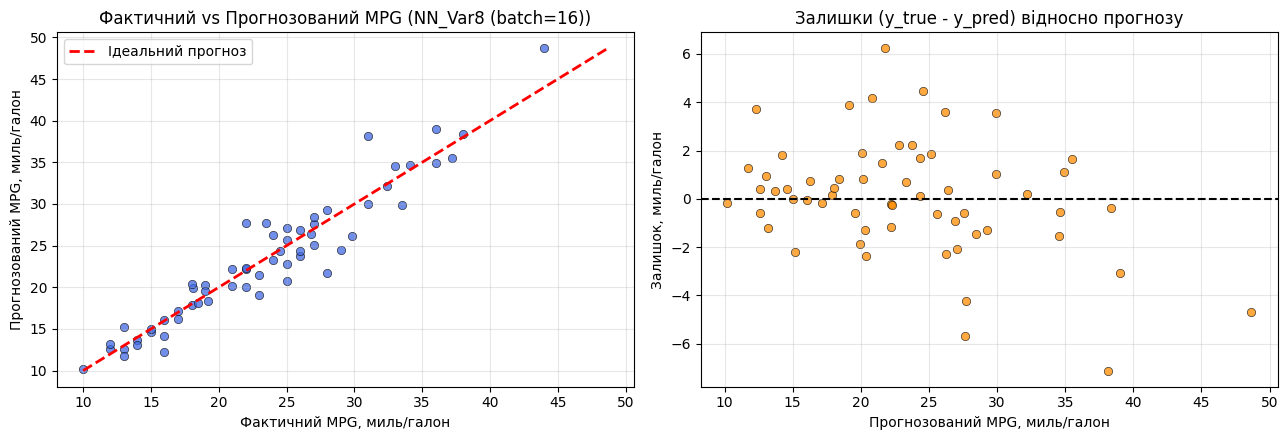

--- Топ-5 найбільших абсолютних помилок на Test ---


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,y_true,y_pred,residual,abs_error
377,4,91.0,68.0,1970.0,17.6,82,3,mazda glc custom,31.0,38.110748,-7.110748,7.110748
30,4,140.0,90.0,2264.0,15.5,71,1,chevrolet vega 2300,28.0,21.770407,6.229593,6.229593
389,6,232.0,112.0,2835.0,14.7,82,1,ford granada l,22.0,27.660765,-5.660765,5.660765
394,4,97.0,52.0,2130.0,24.6,82,2,vw pickup,44.0,48.670563,-4.670563,4.670563
141,4,98.0,83.0,2219.0,16.5,74,2,audi fox,29.0,24.529524,4.470476,4.470476


In [6]:
y_test_pred_nn = test_preds[best_nn_name]
residuals = y_test.to_numpy() - y_test_pred_nn

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Фактичний MPG проти прогнозу
axes[0].scatter(y_test, y_test_pred_nn, alpha=0.75, color="royalblue", edgecolors="k", linewidth=0.5)
lims = [min(y_test.min(), y_test_pred_nn.min()), max(y_test.max(), y_test_pred_nn.max())]
axes[0].plot(lims, lims, "r--", lw=2, label="Ідеальний прогноз")
axes[0].set_title(f"Фактичний vs Прогнозований MPG ({best_nn_name})")
axes[0].set_xlabel("Фактичний MPG, миль/галон")
axes[0].set_ylabel("Прогнозований MPG, миль/галон")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Залишки проти прогнозу
axes[1].scatter(y_test_pred_nn, residuals, alpha=0.75, color="darkorange", edgecolors="k", linewidth=0.5)
axes[1].axhline(0, color="black", linestyle="--", lw=1.5)
axes[1].set_title("Залишки (y_true - y_pred) відносно прогнозу")
axes[1].set_xlabel("Прогнозований MPG, миль/галон")
axes[1].set_ylabel("Залишок, миль/галон")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("lab6_error_plots.png", dpi=300)
plt.show()

# 5 найбільших абсолютних помилок
errors_df = X_test.copy()
errors_df["car_name"] = df.loc[X_test.index, "car_name"]
errors_df["y_true"] = y_test
errors_df["y_pred"] = y_test_pred_nn
errors_df["residual"] = residuals
errors_df["abs_error"] = np.abs(residuals)

print("--- Топ-5 найбільших абсолютних помилок на Test ---")
display(errors_df.sort_values("abs_error", ascending=False).head(5))

In [7]:
best_nn_model.save("artifacts/lab6_model.keras")
joblib.dump(preprocessor, "artifacts/preprocessor.joblib")
if best_overall_name == "LinearRegression":
    joblib.dump(lr_model, "artifacts/best_classic_model.joblib")

metadata = {
    "dataset": "UCI Auto MPG (DOI: 10.24432/C5859H, CC BY 4.0)",
    "target": "mpg",
    "variant": 8,
    "best_nn_model": best_nn_name,
    "best_overall_model": best_overall_name,
    "seed": SEED,
    "raw_features": X.columns.tolist(),
    "transformed_features": feature_names,
    "split_sizes": {"train": len(X_train), "val": len(X_val), "test": len(X_test)},
    "versions": {
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__,
        "tensorflow": tf.__version__,
    }
}
with open("metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Перевірка завантаження та прогнозу на 3 сирих рядках
restored_nn = keras.models.load_model("artifacts/lab6_model.keras")
restored_prep = joblib.load("artifacts/preprocessor.joblib")

raw_sample = X_test.iloc[:3]
pred_before = best_nn_model.predict(preprocessor.transform(raw_sample).astype(np.float32), verbose=0)
pred_after = restored_nn.predict(restored_prep.transform(raw_sample).astype(np.float32), verbose=0)

np.testing.assert_allclose(pred_before, pred_after, rtol=1e-5, atol=1e-6)
print("Артефакти збережено. Перевірка відновлення на 3 сирих рядках пройдена успішно!")

Артефакти збережено. Перевірка відновлення на 3 сирих рядках пройдена успішно!


## Висновок
У ході лабораторної роботи №6 було побудовано конвеєр підготовки табличних даних Auto MPG без витоку інформації (`SimpleImputer` та `OneHotEncoder` навчені виключно на `train`) і порівняно класичні моделі з нейронними мережами TensorFlow. За результатами валідації нейронні мережі значно випередили базовий `DummyRegressor` і показали конкурентну точність порівняно з `LinearRegression`, оскільки здатні враховувати нелінійну залежність витрати пального від маси та об'єму двигуна. Згідно з варіантом №8 зменшення розміру пакету (`batch_size = 16` замість `32`) дозволило мережі частіше оновлювати ваги, забезпечивши на тестовій вибірці показники **Test MAE = ... mpg**, **Test RMSE = ... mpg** та **$R^2 = ...$**. Аналіз 5 найбільших помилок показав, що найбільші відхилення виникають на нетипових або пізніх моделях автомобілів із високою паливною ефективністю (понад 35–40 mpg), де вибірка має меншу щільність спостережень. Обмеженням експерименту є невеликий обсяг набору даних (398 записів 1970–1982 років), тому модель не можна переносити на сучасний автопарк без донавчання.